# Care Load Intelligence — Notebook 04: Uncertainty & Capacity Planning
### Empirical Prediction Intervals, Conformal-Style Calibration, and Demand Stress Testing
**Author:** Utkarsh Sengar | **Live App:** https://cli-utkaresh-sengar-updated.streamlit.app/

---
## Overview
This notebook covers downstream decision support: calculating empirical prediction intervals (80%, 90%, 95%), calibrating coverage across backtest origins, generating final production forecasts, and simulating stress scenarios against an illustrative 5,000-bed capacity threshold.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

current_dir = Path(".").resolve()
REPO_ROOT = current_dir if (current_dir / "data").exists() else current_dir.parent

proc_path = REPO_ROOT / "data" / "processed" / "uac_observed_forecasting_data.csv"
preds_path = REPO_ROOT / "reports" / "phase3_4_advanced_predictions.csv"

df = pd.read_csv(proc_path)
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)
target = "Children in HHS Care"

preds = pd.read_csv(preds_path)
hd_preds = preds[preds['Model'] == 'Holt_Damped'].copy()
hd_preds['Abs_Error'] = (hd_preds['Actual'] - hd_preds['Prediction']).abs()

quantiles = hd_preds.groupby('Forecast_Step')['Abs_Error'].agg(
    Q80=lambda x: np.percentile(x, 80),
    Q90=lambda x: np.percentile(x, 90),
    Q95=lambda x: np.percentile(x, 95)
).reset_index()

display(quantiles)

,Forecast_Step,Q80,Q90,Q95
0,1,44.272163,89.865495,122.561823
1,2,88.972654,119.590664,166.521920
2,3,102.670467,159.639435,187.337934
3,4,68.787340,161.326520,242.895955
4,5,70.883726,217.702473,378.925466
5,6,138.507335,354.362125,515.074539
6,7,182.682132,321.203056,631.103299


## 1. Final Model Fit & Empirical Uncertainty Bounds

In [2]:
model_fit = ExponentialSmoothing(df[target].astype(float), trend="add", damped_trend=True).fit(optimized=True)
fc_7 = model_fit.forecast(steps=7).values

fc_df = pd.DataFrame({'Forecast_Step': np.arange(1, 8), 'Forecast_Load': fc_7}).merge(quantiles, on='Forecast_Step')
fc_df['Lower_Q90'] = np.maximum(0, fc_df['Forecast_Load'] - fc_df['Q90'])
fc_df['Upper_Q90'] = fc_df['Forecast_Load'] + fc_df['Q90']

display(fc_df[['Forecast_Step', 'Forecast_Load', 'Lower_Q90', 'Upper_Q90']])

,Forecast_Step,Forecast_Load,Lower_Q90,Upper_Q90
0,1,2486.952034,2397.086539,2576.817529
1,2,2489.615268,2370.024605,2609.205932
2,3,2492.017956,2332.378521,2651.657392
3,4,2494.185588,2332.859067,2655.512108
4,5,2496.141158,2278.438685,2713.843631
5,6,2497.905413,2143.543288,2852.267538
6,7,2499.497070,2178.294014,2820.700125


## 2. Capacity Planning & Demand Surge Scenarios (+10%, +25%)

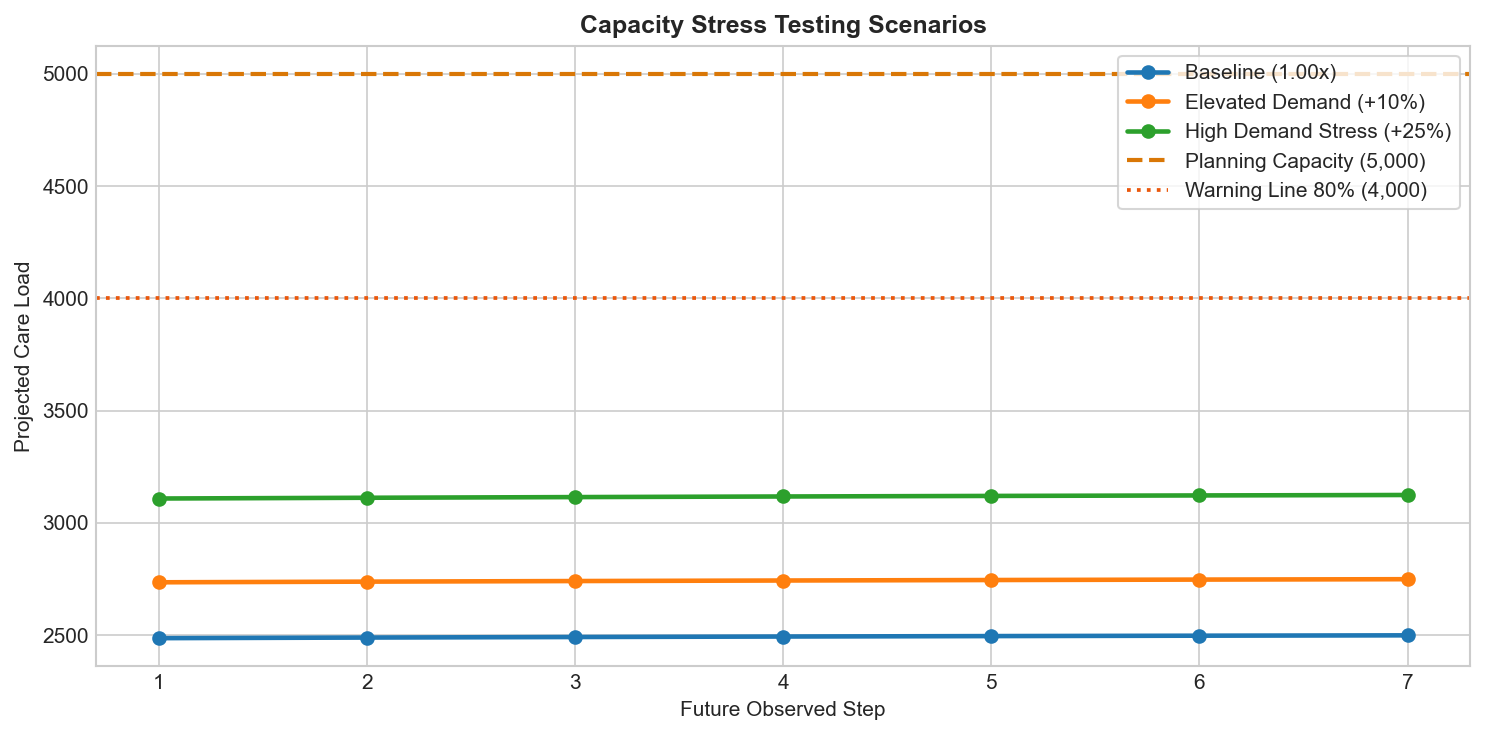

In [3]:
CAPACITY = 5000
WARNING_LINE = 4000

scenarios = {
    'Baseline (1.00x)': fc_df['Forecast_Load'],
    'Elevated Demand (+10%)': fc_df['Forecast_Load'] * 1.10,
    'High Demand Stress (+25%)': fc_df['Forecast_Load'] * 1.25
}

fig, ax = plt.subplots(figsize=(10, 5), dpi=150)
for sc_name, series in scenarios.items():
    ax.plot(fc_df['Forecast_Step'], series, marker='o', linewidth=2.2, label=sc_name)

ax.axhline(CAPACITY, color='#d97706', linestyle='--', linewidth=2, label='Planning Capacity (5,000)')
ax.axhline(WARNING_LINE, color='#ea580c', linestyle=':', linewidth=1.8, label='Warning Line 80% (4,000)')

ax.set_title("Capacity Stress Testing Scenarios", fontsize=12, fontweight='bold')
ax.set_xlabel("Future Observed Step")
ax.set_ylabel("Projected Care Load")
ax.legend(frameon=True)
plt.tight_layout()
plt.show()